# Splits

Builds train/validation/test splits from the hand-off of [02_tiers.ipynb](02_tiers.ipynb): one row per vote with its tier, Gray-coded bits and weight. Every score in the later notebooks is measured on compounds a model was not trained on, and the splits decide which compounds those are. Two schemes are built here, each probing something different; the learned splits of [05_learning_to_split.ipynb](05_learning_to_split.ipynb) come later, in their own file, so rerunning this notebook never erases them.

- **Random 10-fold cross-validation** — the baseline: how well a model does on chemistry like what it was trained on, with ten splits so every score comes with a spread.
- **Cluster 10-fold cross-validation** — the harder test: compounds are clustered by structural similarity and whole clusters are held out, so a test compound's nearest training compound is further away. "Further away" is measured by the same yardstick the last section applies to every scheme, so this split is hard by the measure it is judged on.

What counts as "a compound the model was not trained on" is a decision with teeth. The descriptors used later are blind to stereochemistry, protonation and counter-ions: an enantiomer, a salt, or a drawing without stereo marks is the *same feature vector* as its parent. A model that saw one in training has effectively seen the other. So every scheme groups compounds by **skeleton** — the formula-and-connectivity block of the InChIKey of the largest fragment — and deals whole skeletons to one side. Grouping only salts with their parents, the usual habit, would leave several hundred stereo and protonation siblings straddling train and test.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from rdkit import Chem, RDLogger
from rdkit.Chem.MolStandardize import rdMolStandardize

RDLogger.DisableLog("rdApp.warning")  # AqSolDB's [H+]/hydride fragments warn on every parse
RDLogger.DisableLog("rdApp.info")  # the standardizer logs every step it takes

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
votes = pd.read_csv(ROOT / "data" / "aqsoldb_tiers.csv")  # one row per vote, written by 02_tiers.ipynb

# One row per compound. The skeleton is the first block of the InChIKey of the largest fragment: formula and connectivity
# only, so stereoisomers, protonation states, isotopes and salts of one skeleton share a group.
compounds = votes.groupby("InChIKey").agg(
    SMILES=("SMILES", "first"), votes=("SMILES", "size"), unflagged=("flagged", lambda f: int((~f).sum()))
)
choose = rdMolStandardize.LargestFragmentChooser()
fragments = [choose.choose(Chem.MolFromSmiles(s)) for s in compounds["SMILES"]]
compounds["skeleton"] = [Chem.MolToInchiKey(m)[:14] for m in fragments]
assert compounds["skeleton"].str.len().eq(14).all(), "RDKit could not generate a skeleton key"

shared = compounds.groupby("skeleton")["skeleton"].transform("size") > 1
print(
    f"{len(votes)} votes, {len(compounds)} compounds, {compounds['skeleton'].nunique()} skeletons; "
    f"{shared.sum()} compounds share a skeleton with another compound"
)

12097 votes, 9946 compounds, 9158 skeletons; 1281 compounds share a skeleton with another compound


## Cross-validation splits (baseline)

Skeletons are shuffled with a fixed seed and dealt into 10 folds holding about equal numbers of compounds. Split $k$ uses fold $k$ as its test set, the next fold (wrapping round) as validation, and the other eight for training: 80/10/10, with every compound tested exactly once and validated exactly once. The number of folds and the validation rule are our choice. With one model trained per split, the spread of its scores across the 10 splits measures sampling uncertainty: how much the score depends on which compounds land on each side. The training sets share most of their compounds, so that spread understates the uncertainty somewhat; the later notebooks correct the standard error for this overlap.

These splits measure performance on chemistry like the training set, and the other schemes are compared against them. Each test set also holds compounds with two or more unflagged votes — the only ones on which a model can be compared with the repeat-measurement benchmark of the tiers notebook (0.96 bits held out, 76.5% in the same tier).

In [2]:
SIDES = ["train", "validation", "test"]
FOLDS, SEED = 10, 0
CV_SPLITS = [f"cv_{k}" for k in range(FOLDS)]


def assign_folds(group: pd.Series, folds: int, seed: int) -> pd.Series:
    """Fold per compound, dealing whole groups so each fold holds about the same number of compounds."""
    sizes = group.value_counts().sort_index().sample(frac=1, random_state=seed)  # compounds per group, shuffled
    return group.map(pd.cut(sizes.cumsum() / sizes.sum(), np.linspace(0, 1, folds + 1), labels=False))


def sides(fold: pd.Series, k: int) -> np.ndarray:
    """train / validation / test per compound for split k: test = fold k, validation = fold k + 1 (wrapping round)."""
    return np.select([fold == k, fold == (k + 1) % FOLDS], ["test", "validation"], "train")


def describe(split: str) -> pd.DataFrame:
    """Compounds and tier shares per side; tier shares use the vote weights, so every compound counts once."""
    tiers = votes.groupby([votes["InChIKey"].map(compounds[split]), "tier"])["weight"].sum().unstack()
    return pd.DataFrame(
        {
            "compounds": compounds[split].value_counts(),
            "with 2+ unflagged votes": compounds.loc[compounds["unflagged"] >= 2, split].value_counts(),
        }
    ).join((100 * tiers.div(tiers.sum(axis=1), axis=0)).add_prefix("% tier "))


def check(splits: list[str], fold: str, group: str) -> None:
    assert compounds.groupby(group)[fold].nunique().eq(1).all(), f"a {group} straddles two folds"
    assert all(set(compounds[split]) == set(SIDES) for split in splits), "a split is missing train, validation or test"
    for side in ["test", "validation"]:
        assert (compounds[splits] == side).sum(axis=1).eq(1).all(), f"a compound is not in exactly one {side} set"


def ranges(splits: list[str]) -> pd.DataFrame:
    """min–max over the splits of each side's description."""
    per_split = pd.concat({split: describe(split) for split in splits}, names=["split", "side"]).groupby("side")
    return (per_split.min().round(1).astype(str) + "–" + per_split.max().round(1).astype(str)).loc[SIDES]


compounds["fold"] = assign_folds(compounds["skeleton"], FOLDS, SEED)
for k, split in enumerate(CV_SPLITS):
    compounds[split] = sides(compounds["fold"], k)
check(CV_SPLITS, "fold", "skeleton")
fold_sizes = compounds["fold"].value_counts()
print(
    f"{FOLDS} folds of {fold_sizes.min()}–{fold_sizes.max()} compounds; "
    "each split has train, validation and test, and every compound is in exactly one test and one validation set"
)
ranges(CV_SPLITS)

10 folds of 994–995 compounds; each split has train, validation and test, and every compound is in exactly one test and one validation set


,compounds,with 2+ unflagged votes,% tier 0,% tier 1,% tier 2,% tier 3
side,,,,,,
train,7956–7957,1248–1288,15.5–16.2,21.9–22.9,31.5–32.1,29.5–30.3
validation,994–995,133–176,14.3–18.4,19.5–25.6,29.9–34.1,27.5–31.7
test,994–995,133–176,14.3–18.4,19.5–25.6,29.9–34.1,27.5–31.7


## Cluster splits

The cross-validation folds hold out compounds at random, so a test compound usually has a close relative in training. The second scheme holds out *neighbourhoods* instead: compounds are clustered by structural similarity and whole clusters are dealt to the folds, so a test compound's nearest training compound is further away. Similarity is the Tanimoto similarity between Morgan fingerprints (radius 2, 2048 bits) of the largest fragment.

Clusters come from sphere exclusion, the leader algorithm: walk the compounds in order, make a compound a centre if it lies further than a threshold distance from every centre so far, then assign every compound to its nearest centre. Each skeleton takes the cluster of its first member, so skeleton grouping is preserved. The threshold sets how far apart test and train end up. The sweep below shows, for each threshold, how many clusters form, whether the folds stay balanced, and how similar test compounds' nearest training neighbours are. The rule for the threshold is declared before the sweep (our choice): the smallest distance at which **no test compound has an identical fingerprint in training** — the point at which holding out a cluster really does hold out its neighbourhood — provided the folds stay within a few percent of equal size.

In [3]:
from rdkit import DataStructs
from rdkit.Chem import rdFingerprintGenerator
from rdkit.SimDivFilters import rdSimDivPickers

THRESHOLDS = [0.3, 0.4, 0.5, 0.6]  # Tanimoto distance from a cluster centre; the sweep is our choice
CLUSTER_SPLITS = [f"cluster_{k}" for k in range(FOLDS)]

generator = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fingerprints = [generator.GetFingerprint(m) for m in fragments]


def nearest_train_similarity(where: np.ndarray) -> pd.Series:
    """For each compound on the test side of `where`, the Tanimoto similarity to its most similar training compound."""
    train = [fingerprints[i] for i in np.flatnonzero(where == "train")]
    test = np.flatnonzero(where == "test")
    return pd.Series([max(DataStructs.BulkTanimotoSimilarity(fingerprints[i], train)) for i in test], index=compounds.index[test])


def sphere_clusters(threshold: float) -> pd.Series:
    """Leader clustering: centres further than `threshold` from each other, every compound to its nearest centre."""
    centres = list(rdSimDivPickers.LeaderPicker().LazyBitVectorPick(fingerprints, len(fingerprints), threshold))
    centre_fps = [fingerprints[i] for i in centres]
    cluster = pd.Series([int(np.argmax(DataStructs.BulkTanimotoSimilarity(fp, centre_fps))) for fp in fingerprints], index=compounds.index)
    return cluster.groupby(compounds["skeleton"]).transform("first")  # one cluster per skeleton


sweep, by_threshold = [], {}
for threshold in THRESHOLDS:
    cluster = sphere_clusters(threshold)
    fold = assign_folds(cluster, FOLDS, SEED)
    similarity = pd.concat([nearest_train_similarity(sides(fold, k)) for k in range(FOLDS)])
    by_threshold[threshold] = (cluster, fold, similarity)
    sizes = cluster.value_counts()
    sweep.append(
        {
            "distance threshold": threshold,
            "clusters": len(sizes),
            "largest cluster": int(sizes.max()),
            "single-compound clusters": int((sizes == 1).sum()),
            "fold size (min–max)": f"{fold.value_counts().min()}–{fold.value_counts().max()}",
            "nearest-train similarity (median)": similarity.median(),
            "% identical fingerprint in training": 100 * (similarity >= 1 - 1e-9).mean(),
        }
    )
sweep = pd.DataFrame(sweep).set_index("distance threshold")
leak_free = sweep.index[sweep["% identical fingerprint in training"] == 0]
assert len(leak_free), "no threshold in the sweep removes every identical fingerprint; widen the sweep"
THRESHOLD = float(leak_free.min())

compounds["cluster"], compounds["cluster_fold"], _ = by_threshold[THRESHOLD]
for k, split in enumerate(CLUSTER_SPLITS):
    compounds[split] = sides(compounds["cluster_fold"], k)
check(CLUSTER_SPLITS, "cluster_fold", "skeleton")
print(f"chosen distance threshold: {THRESHOLD} (similarity to the cluster centre at least {1 - THRESHOLD:.1f})")
display(sweep.round(3))
ranges(CLUSTER_SPLITS)

chosen distance threshold: 0.6 (similarity to the cluster centre at least 0.4)


,clusters,largest cluster,single-compound clusters,fold size (min–max),nearest-train similarity (median),% identical fingerprint in training
distance threshold,,,,,,
0.3,7503,24,6159,992–997,0.571,0.332
0.4,6126,33,4346,991–999,0.538,0.332
0.5,4429,49,2418,983–1002,0.500,0.332
0.6,3039,61,1268,978–1007,0.471,0.000


,compounds,with 2+ unflagged votes,% tier 0,% tier 1,% tier 2,% tier 3
side,,,,,,
train,7941–7972,1240–1294,15.4–16.5,21.9–22.7,31.2–32.2,29.4–30.5
validation,978–1007,133–172,9.4–19.1,19.7–24.5,26.0–36.3,25.4–33.3
test,978–1007,133–172,9.4–19.1,19.7–24.5,26.0–36.3,25.4–33.3


## How far each scheme pushes the test set from training

A split is only as hard as the chemistry it holds out. For every compound, take the fingerprint of its largest fragment and find the most similar training compound, by Tanimoto similarity, on the split where that compound is tested; both schemes test every compound once, so each gives one number per compound. The table shows the quartiles and the share of test compounds whose fingerprint also occurs in training — a near-duplicate the skeleton grouping did not catch. The learned splits will be measured the same way in their notebook, so all three schemes sit on one axis: how familiar the test chemistry is.

,25th percentile,median,75th percentile,% with an identical fingerprint in training
random cross-validation,0.476,0.594,0.714,4.655
cluster cross-validation,0.385,0.471,0.571,0.000


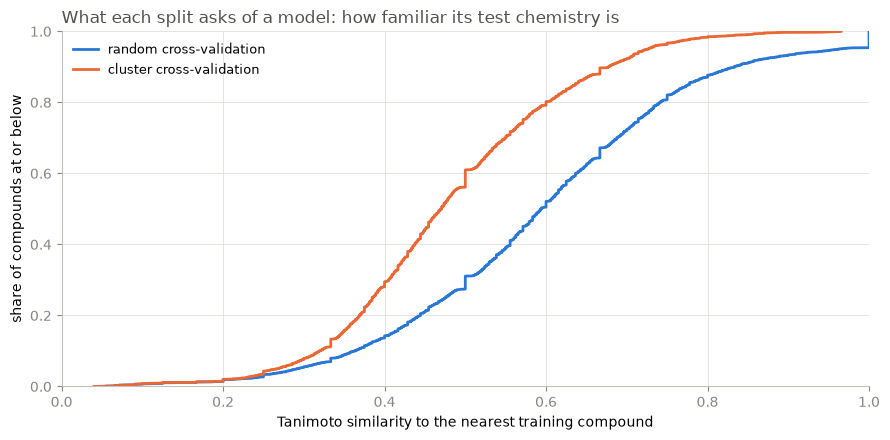

In [4]:
import matplotlib.pyplot as plt

nearest = {
    "random cross-validation": pd.concat([nearest_train_similarity(sides(compounds["fold"], k)) for k in range(FOLDS)]),
    "cluster cross-validation": by_threshold[THRESHOLD][2],
}
assert all(len(s) == len(compounds) for s in nearest.values())
display(
    pd.DataFrame(
        {
            name: {
                "25th percentile": s.quantile(0.25),
                "median": s.median(),
                "75th percentile": s.quantile(0.75),
                "% with an identical fingerprint in training": 100 * (s >= 1 - 1e-9).mean(),
            }
            for name, s in nearest.items()
        }
    ).T.round(3)
)

INK, MUTED, GRID, AXIS = "#52514e", "#898781", "#e1e0d9", "#c3c2b7"  # as in 01_prep_and_analysis.ipynb
SERIES = ["#2a78d6", "#eb6834"]
fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, s), color in zip(nearest.items(), SERIES):
    x = np.sort(s.to_numpy())
    ax.plot(x, np.arange(1, len(x) + 1) / len(x), color=color, lw=2, label=name)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(AXIS)
ax.tick_params(colors=MUTED)
ax.grid(color=GRID, lw=0.6)
ax.set_axisbelow(True)
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel="Tanimoto similarity to the nearest training compound", ylabel="share of compounds at or below")
ax.set_title("What each split asks of a model: how familiar its test chemistry is", loc="left", color=INK)
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout()

The cluster splits are the harder test: the nearest training neighbour of a test compound is noticeably less similar than under random cross-validation, and no test compound has an identical fingerprint in training, where random cross-validation leaves a few percent — positional isomers and homologues that a 2048-bit fingerprint cannot tell apart even after skeleton grouping. That is the regime the baseline measures, and it should be read as such: performance on familiar chemistry. The tier mix per side wanders more under the cluster scheme than under random folds — a held-out neighbourhood can be a solubility neighbourhood too, so single test sets range from 9% to 19% in the least soluble tier against 14–18% at random — but it stays centred on the overall mix across the ten splits, so the scheme is not hard because a tier moved into test; any model scored on it should still be scored over all ten splits, not one.

## Hand-off

One row per compound, joined to the vote-level file on InChIKey: the skeleton; the random fold and its ten `cv_` columns; the cluster, its fold and the ten `cluster_` columns — each column holding `train`, `validation` or `test`. Later schemes write their own files with the same layout. Next, [04_features.ipynb](04_features.ipynb) uses the cross-validation splits to compare chemical representations.

In [5]:
compounds[["skeleton", "fold", *CV_SPLITS, "cluster", "cluster_fold", *CLUSTER_SPLITS]].to_csv(ROOT / "data" / "aqsoldb_splits.csv")
print(f"{len(compounds)} compounds, {len(CV_SPLITS)} random and {len(CLUSTER_SPLITS)} cluster cross-validation splits -> data/aqsoldb_splits.csv")

9946 compounds, 10 random and 10 cluster cross-validation splits -> data/aqsoldb_splits.csv
